In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split, Subset
from torchvision.datasets import FashionMNIST
from torchvision.transforms import ToTensor
import numpy as np
import matplotlib.pyplot as plt
import copy
import time
import json

SEED = 42
BATCH_SIZE = 128
INIT_LR = 0.001

def set_seed():
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
hardware = torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU"
print("Device:", device, hardware)

allTrainData = FashionMNIST("data", train=True, download=True, transform=ToTensor())
trainData, valData = random_split(
    allTrainData, [54000, 6000], generator=torch.Generator().manual_seed(SEED)
)
sample_indices = torch.randperm(
    len(trainData), generator=torch.Generator().manual_seed(SEED)
)[:6000].tolist()
trainEvalData = Subset(trainData, sample_indices)

def make_train_loader(data):
    return DataLoader(data, batch_size=BATCH_SIZE, shuffle=True,
                      generator=torch.Generator().manual_seed(SEED))

valLoader = DataLoader(valData, batch_size=BATCH_SIZE, shuffle=False)
trainEvalLoader = DataLoader(trainEvalData, batch_size=BATCH_SIZE, shuffle=False)
print("Train:", len(trainData), "Validation:", len(valData))
print("Training evaluation sample:", len(trainEvalData))





Device: cuda Tesla T4


100%|██████████| 26.4M/26.4M [00:02<00:00, 12.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.80MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.4MB/s]

Train: 54000 Validation: 6000
Training evaluation sample: 6000


In [2]:
class ModelA(nn.Module):
    def __init__(self):
        super(ModelA, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=5, padding=2)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.relu3 = nn.ReLU()
        self.fc1 = nn.Linear(128 * 7 * 7, 128)
        self.relu4 = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.relu3(self.conv3(x))
        x = torch.flatten(x, 1)
        x = self.relu4(self.fc1(x))
        return self.fc2(x)

class ModelB(nn.Module):
    def __init__(self):
        super(ModelB, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)
        self.conv2_1 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
        self.relu2_1 = nn.ReLU()
        self.conv2_2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.relu2_2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.relu3 = nn.ReLU()
        self.fc1 = nn.Linear(128 * 7 * 7, 128)
        self.relu4 = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.relu2_1(self.conv2_1(x))
        x = self.pool2(self.relu2_2(self.conv2_2(x)))
        x = self.relu3(self.conv3(x))
        x = torch.flatten(x, 1)
        x = self.relu4(self.fc1(x))
        return self.fc2(x)


In [3]:
class BaseNet(nn.Module):
    def __init__(self, use_bn=False, use_dropout=False):
        super(BaseNet, self).__init__()
        self.use_bn = use_bn
        self.use_dropout = use_dropout

        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32) if use_bn else nn.Identity()
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=5, padding=2)
        self.bn2 = nn.BatchNorm2d(64) if use_bn else nn.Identity()
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128) if use_bn else nn.Identity()
        self.relu3 = nn.ReLU()

        self.fc1 = nn.Linear(128 * 7 * 7, 128)
        self.dropout = nn.Dropout(p=0.35) if use_dropout else nn.Identity()
        self.relu4 = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.bn1(self.conv1(x))))
        x = self.pool2(self.relu2(self.bn2(self.conv2(x))))
        x = self.relu3(self.bn3(self.conv3(x)))
        x = torch.flatten(x, 1)
        x = self.dropout(self.relu4(self.fc1(x)))
        return self.fc2(x)


In [4]:
class ModelD1(nn.Module):
    def __init__(self):
        super(ModelD1, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=5, padding=2)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.relu3 = nn.ReLU()
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.relu3(self.conv3(x))
        x = self.gap(x)
        x = torch.flatten(x, 1)
        return self.fc(x)

class ModelD2(nn.Module):
    def __init__(self):
        super(ModelD2, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=5, padding=2)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.relu3 = nn.ReLU()
        self.adaptive_pool = nn.AdaptiveAvgPool2d((2, 2))
        self.fc1 = nn.Linear(128 * 2 * 2, 48)
        self.relu4 = nn.ReLU()
        self.fc2 = nn.Linear(48, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.relu3(self.conv3(x))
        x = self.adaptive_pool(x)
        x = torch.flatten(x, 1)
        x = self.relu4(self.fc1(x))
        return self.fc2(x)


In [5]:
lossFn = nn.CrossEntropyLoss()

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            pred = model(x)
            total_loss += lossFn(pred, y).item() * y.size(0)
            correct += (pred.argmax(1) == y).sum().item()
            total += y.size(0)
    return total_loss / total, correct / total

def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize()

def train_model(name, model, data, evaluation_loader, epochs):
    model = model.to(device)
    loader = make_train_loader(data)
    optimizer = torch.optim.Adam(model.parameters(), lr=INIT_LR)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_loss = float("inf")
    best_epoch = 0
    best_state = None
    synchronize()
    start = time.perf_counter()

    for epoch in range(epochs):
        model.train()
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = lossFn(model(x), y)
            loss.backward()
            optimizer.step()

        train_loss, train_acc = evaluate(model, evaluation_loader)
        val_loss, val_acc = evaluate(model, valLoader)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())
        print(f"{name} {epoch+1:02d}/{epochs} | Train Loss {train_loss:.4f} Acc {train_acc:.4f} | Val Loss {val_loss:.4f} Acc {val_acc:.4f}")

    synchronize()
    seconds = time.perf_counter() - start
    model.load_state_dict(best_state)
    model.eval()
    index = best_epoch - 1
    maximum_acc = max(history["val_acc"])
    summary = {"name": name, "parameters": count_parameters(model),
               "epochs": epochs, "best_loss_epoch": best_epoch,
               "validation_loss": history["val_loss"][index],
               "validation_accuracy": history["val_acc"][index],
               "train_eval_loss": history["train_loss"][index],
               "train_eval_accuracy": history["train_acc"][index],
               "train_eval_count": len(evaluation_loader.dataset),
               "gap_percentage_points": 100 * (history["train_acc"][index] - history["val_acc"][index]),
               "maximum_validation_accuracy": maximum_acc,
               "maximum_accuracy_epoch": history["val_acc"].index(maximum_acc) + 1,
               "training_and_evaluation_seconds": seconds}
    print(json.dumps(summary, indent=2))
    return {"model": model, "history": history, "summary": summary}

def plot_results(results):
    plt.figure(figsize=(13, 9))
    for panel, metric in enumerate(["loss", "acc"]):
        for column, split in enumerate(["train", "val"]):
            plt.subplot(2, 2, panel * 2 + column + 1)
            for name, result in results.items():
                h = result["history"]
                plt.plot(range(1, len(h[split + "_" + metric]) + 1),
                         h[split + "_" + metric], marker="o", label=name)
            plt.xlabel("Epoch")
            plt.ylabel(metric)
            plt.title(split + " " + metric + " (eval)")
            plt.grid(True)
            plt.legend()
    plt.tight_layout()
    plt.show()
    plt.close()


In [7]:
# A
set_seed()
baseline = ModelA().to(device)
baseline.eval()
shape_rows = []
with torch.no_grad():
    x = torch.zeros(2, 1, 28, 28).to(device)
    for name, layer in baseline.named_children():
        if name == "fc1":
            x = torch.flatten(x, 1)
            shape_rows.append({"layer": "flatten", "shape": str(list(x.shape))})
        x = layer(x)
        shape_rows.append({"layer": name, "shape": str(list(x.shape))})
        print(name, list(x.shape))
    assert list(x.shape) == [2, 10]

parameter_rows = []
for name in ["conv1", "conv2", "conv3", "fc1", "fc2"]:
    row = {"layer": name, "parameters": count_parameters(getattr(baseline, name))}
    parameter_rows.append(row)
    print(row)
parameter_rows.append({"layer": "total", "parameters": count_parameters(baseline)})
assert count_parameters(baseline) == 929674

rf_rows = []
rf, jump = 1, 1
for name, kernel, stride in [("input", 1, 1), ("conv1", 3, 1), ("pool1", 2, 2),
                              ("conv2", 5, 1), ("pool2", 2, 2), ("conv3", 3, 1)]:
    rf = rf + (kernel - 1) * jump
    jump = jump * stride
    rf_rows.append({"layer": name, "kernel": kernel, "stride": stride, "RF": rf, "jump": jump})
    print(rf_rows[-1])
assert rf == 22 and jump == 4


conv1 [2, 32, 28, 28]
relu1 [2, 32, 28, 28]
pool1 [2, 32, 14, 14]
conv2 [2, 64, 14, 14]
relu2 [2, 64, 14, 14]
pool2 [2, 64, 7, 7]
conv3 [2, 128, 7, 7]
relu3 [2, 128, 7, 7]
fc1 [2, 128]
relu4 [2, 128]
fc2 [2, 10]
{'layer': 'conv1', 'parameters': 320}
{'layer': 'conv2', 'parameters': 51264}
{'layer': 'conv3', 'parameters': 73856}
{'layer': 'fc1', 'parameters': 802944}
{'layer': 'fc2', 'parameters': 1290}
{'layer': 'input', 'kernel': 1, 'stride': 1, 'RF': 1, 'jump': 1}
{'layer': 'conv1', 'kernel': 3, 'stride': 1, 'RF': 3, 'jump': 1}
{'layer': 'pool1', 'kernel': 2, 'stride': 2, 'RF': 4, 'jump': 2}
{'layer': 'conv2', 'kernel': 5, 'stride': 1, 'RF': 12, 'jump': 2}
{'layer': 'pool2', 'kernel': 2, 'stride': 2, 'RF': 14, 'jump': 4}
{'layer': 'conv3', 'kernel': 3, 'stride': 1, 'RF': 22, 'jump': 4}


A_baseline 01/8 | Train Loss 0.3416 Acc 0.8800 | Val Loss 0.3640 Acc 0.8705
A_baseline 02/8 | Train Loss 0.2798 Acc 0.8937 | Val Loss 0.3109 Acc 0.8890
A_baseline 03/8 | Train Loss 0.2113 Acc 0.9235 | Val Loss 0.2545 Acc 0.9037
A_baseline 04/8 | Train Loss 0.2060 Acc 0.9255 | Val Loss 0.2549 Acc 0.9080
A_baseline 05/8 | Train Loss 0.1884 Acc 0.9288 | Val Loss 0.2433 Acc 0.9100
A_baseline 06/8 | Train Loss 0.1572 Acc 0.9433 | Val Loss 0.2409 Acc 0.9130
A_baseline 07/8 | Train Loss 0.1358 Acc 0.9500 | Val Loss 0.2273 Acc 0.9160
A_baseline 08/8 | Train Loss 0.1043 Acc 0.9640 | Val Loss 0.2099 Acc 0.9232
{
  "name": "A_baseline",
  "parameters": 929674,
  "epochs": 8,
  "best_loss_epoch": 8,
  "validation_loss": 0.2098998260498047,
  "validation_accuracy": 0.9231666666666667,
  "train_eval_loss": 0.10428523854414622,
  "train_eval_accuracy": 0.964,
  "train_eval_count": 6000,
  "gap_percentage_points": 4.083333333333328,
  "maximum_validation_accuracy": 0.9231666666666667,
  "maximum_accur

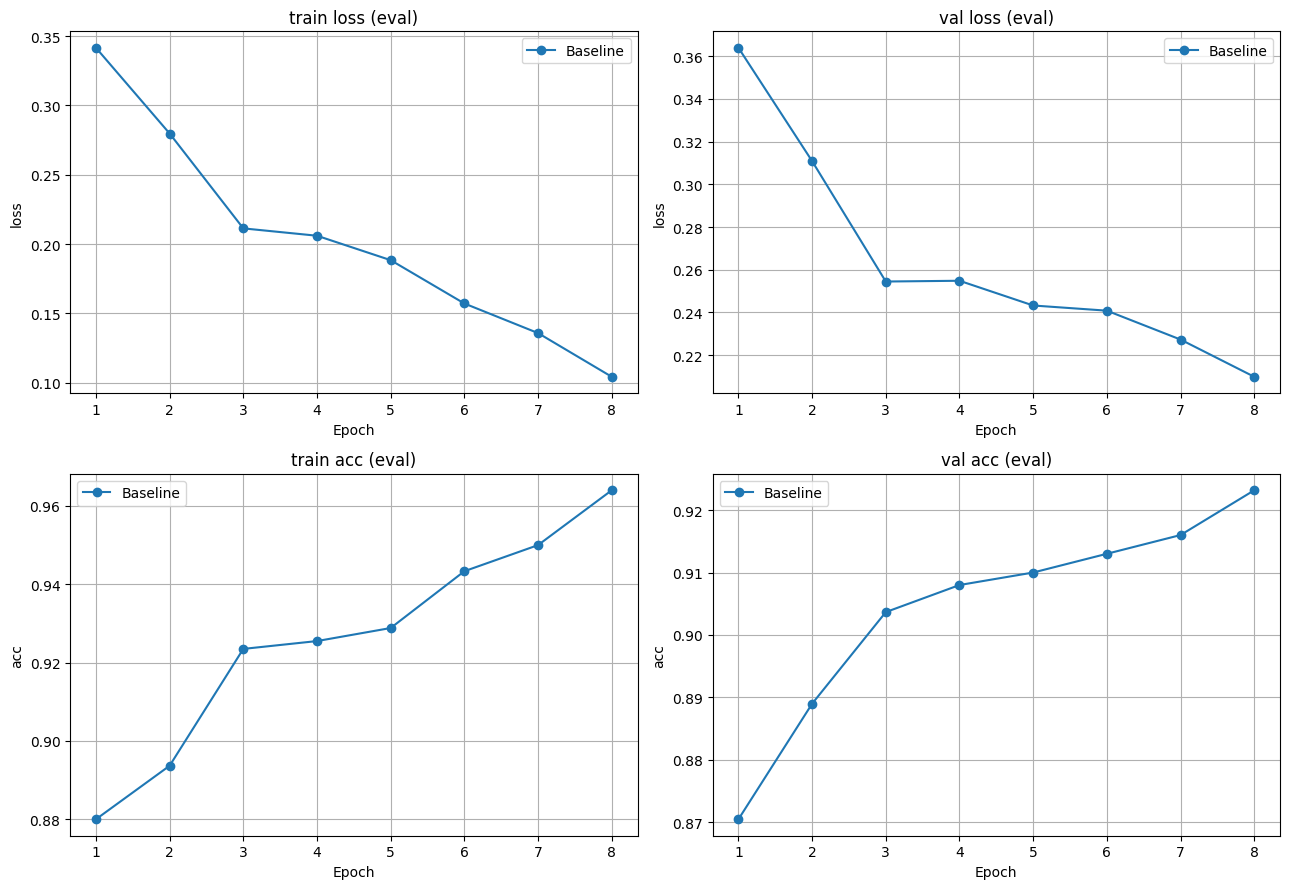

In [8]:
set_seed()
result_A = train_model("A_baseline", ModelA(), trainData, trainEvalLoader, 8)
plot_results({'Baseline': result_A})
baseline = result_A["model"]


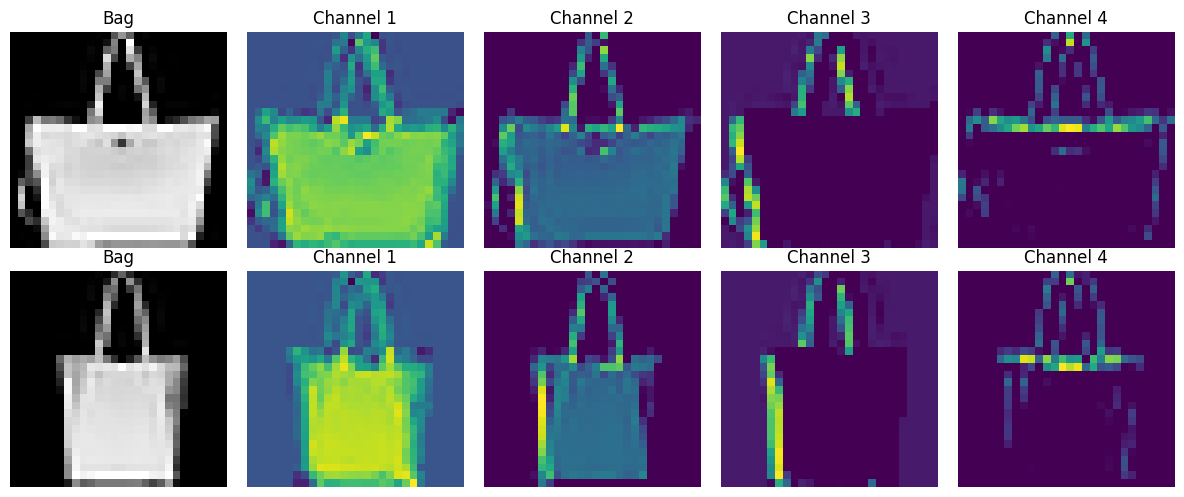

In [9]:
images, labels = next(iter(valLoader))
baseline.eval()
with torch.no_grad():
    features = baseline.relu1(baseline.conv1(images[:2].to(device))).cpu()
plt.figure(figsize=(12, 5))
for row in range(2):
    plt.subplot(2, 5, row * 5 + 1)
    plt.imshow(images[row].squeeze(), cmap="gray")
    plt.title(allTrainData.classes[labels[row].item()])
    plt.axis("off")
    for channel in range(4):
        plt.subplot(2, 5, row * 5 + channel + 2)
        plt.imshow(features[row, channel], cmap="viridis")
        plt.title(f"Channel {channel+1}")
        plt.axis("off")
plt.tight_layout()
plt.show()
plt.close()


{'middle_A': 51264, 'middle_B': 27744, 'total_A': 929674, 'total_B': 906154, 'middle_reduction_percent': 45.88014981273408, 'total_reduction_percent': 2.5299190899175428}
[{'model': 'A', 'position': 'middle_input', 'RF': 4, 'jump': 2}, {'model': 'A', 'position': 'middle_output', 'RF': 12, 'jump': 2}, {'model': 'A', 'position': 'last_feature_map', 'RF': 22, 'jump': 4}, {'model': 'B', 'position': 'middle_input', 'RF': 4, 'jump': 2}, {'model': 'B', 'position': 'middle_output', 'RF': 12, 'jump': 2}, {'model': 'B', 'position': 'last_feature_map', 'RF': 22, 'jump': 4}]
B_two_small_filters 01/8 | Train Loss 0.3529 Acc 0.8697 | Val Loss 0.3742 Acc 0.8670
B_two_small_filters 02/8 | Train Loss 0.3030 Acc 0.8858 | Val Loss 0.3269 Acc 0.8815
B_two_small_filters 03/8 | Train Loss 0.2405 Acc 0.9110 | Val Loss 0.2794 Acc 0.8967
B_two_small_filters 04/8 | Train Loss 0.2162 Acc 0.9242 | Val Loss 0.2531 Acc 0.9080
B_two_small_filters 05/8 | Train Loss 0.1913 Acc 0.9298 | Val Loss 0.2463 Acc 0.9135
B_two

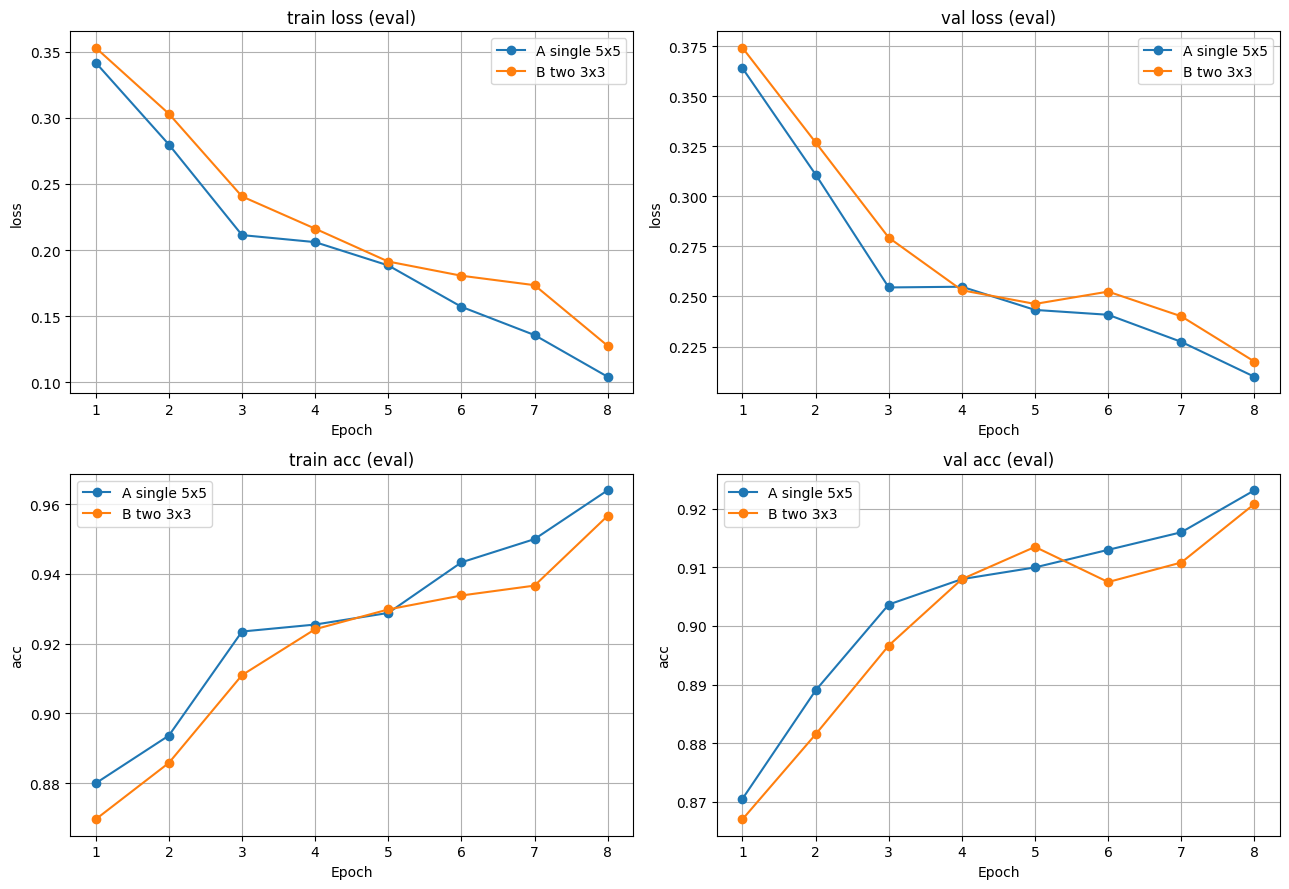

In [10]:
# B
set_seed()
model_b = ModelB()
middle_a = count_parameters(baseline.conv2)
middle_b = count_parameters(model_b.conv2_1) + count_parameters(model_b.conv2_2)
comparison_B = {"middle_A": middle_a, "middle_B": middle_b,
                "total_A": count_parameters(baseline), "total_B": count_parameters(model_b),
                "middle_reduction_percent": 100 * (1 - middle_b / middle_a),
                "total_reduction_percent": 100 * (1 - count_parameters(model_b) / count_parameters(baseline))}
print(comparison_B)

rf_B = []
for name, kernels in [("A", [5]), ("B", [3, 3])]:
    rf, jump = 4, 2
    rf_B.append({"model": name, "position": "middle_input", "RF": rf, "jump": jump})
    for kernel in kernels:
        rf += (kernel - 1) * jump
    rf_B.append({"model": name, "position": "middle_output", "RF": rf, "jump": jump})
    rf += jump
    jump *= 2
    rf += 2 * jump
    rf_B.append({"model": name, "position": "last_feature_map", "RF": rf, "jump": jump})
print(rf_B)

set_seed()
result_B = train_model("B_two_small_filters", ModelB(), trainData, trainEvalLoader, 8)
plot_results({'A single 5x5': result_A, 'B two 3x3': result_B})


C training class counts: [500 500 500 500 500 500 500 500 500 500]
C_base 01/18 | Train Loss 0.8822 Acc 0.6218 | Val Loss 0.9142 Acc 0.6185
C_base 02/18 | Train Loss 0.5998 Acc 0.7606 | Val Loss 0.6503 Acc 0.7437
C_base 03/18 | Train Loss 0.5088 Acc 0.8012 | Val Loss 0.5618 Acc 0.7905
C_base 04/18 | Train Loss 0.4623 Acc 0.8260 | Val Loss 0.5456 Acc 0.8027
C_base 05/18 | Train Loss 0.3800 Acc 0.8598 | Val Loss 0.4585 Acc 0.8360
C_base 06/18 | Train Loss 0.3616 Acc 0.8680 | Val Loss 0.4494 Acc 0.8363
C_base 07/18 | Train Loss 0.3713 Acc 0.8628 | Val Loss 0.4642 Acc 0.8370
C_base 08/18 | Train Loss 0.3153 Acc 0.8852 | Val Loss 0.4353 Acc 0.8497
C_base 09/18 | Train Loss 0.2907 Acc 0.8988 | Val Loss 0.4004 Acc 0.8548
C_base 10/18 | Train Loss 0.2973 Acc 0.8926 | Val Loss 0.4408 Acc 0.8437
C_base 11/18 | Train Loss 0.3229 Acc 0.8718 | Val Loss 0.4582 Acc 0.8410
C_base 12/18 | Train Loss 0.2147 Acc 0.9242 | Val Loss 0.3690 Acc 0.8740
C_base 13/18 | Train Loss 0.3437 Acc 0.8764 | Val Loss 0.

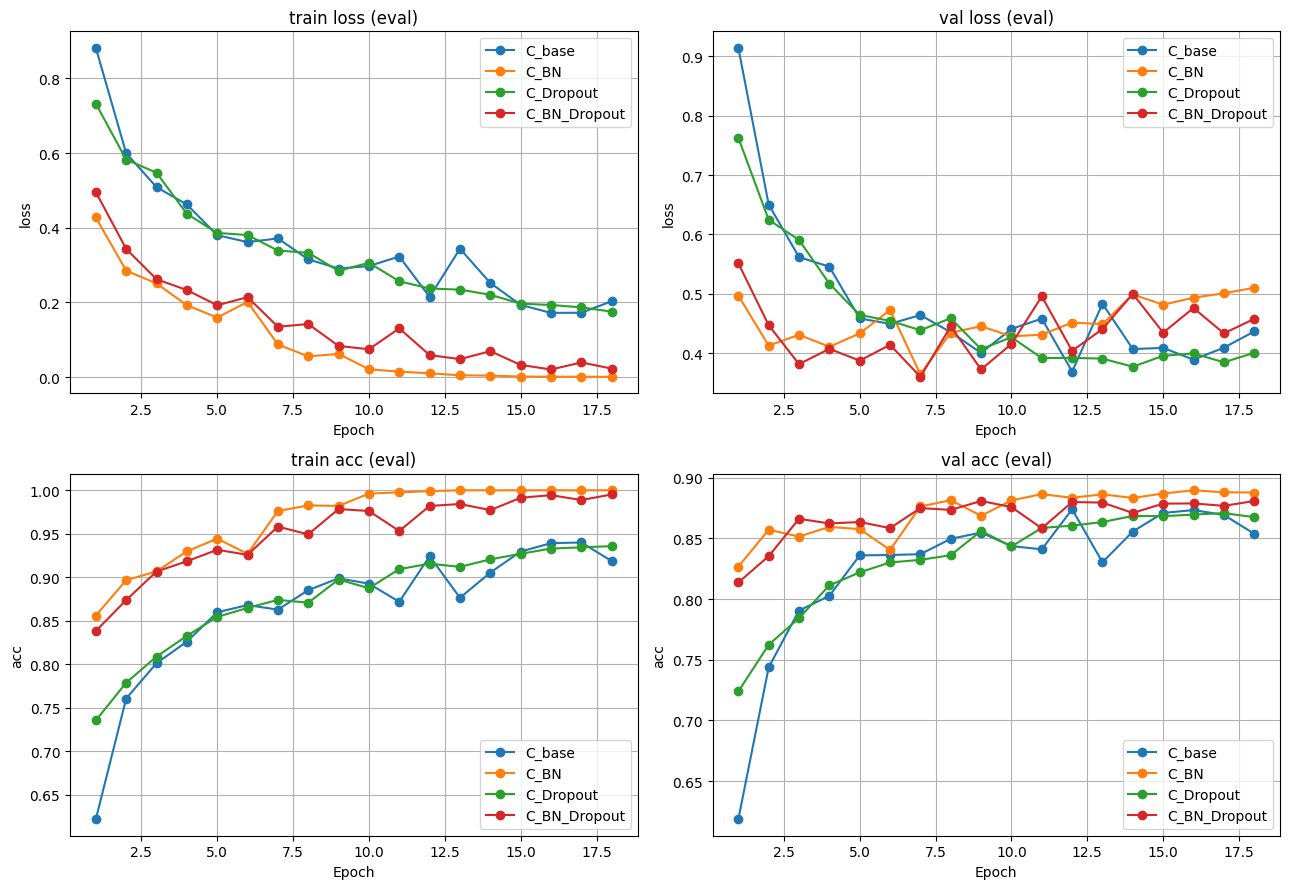

C_base gap (percentage points): 5.02 validation accuracy: 0.874 min-loss epoch: 12 max-accuracy epoch: 12
C_BN gap (percentage points): 9.987 validation accuracy: 0.8763 min-loss epoch: 7 max-accuracy epoch: 16
C_Dropout gap (percentage points): 5.21 validation accuracy: 0.8685 min-loss epoch: 14 max-accuracy epoch: 17
C_BN_Dropout gap (percentage points): 8.32 validation accuracy: 0.875 min-loss epoch: 7 max-accuracy epoch: 9


In [11]:
# C
train_targets = allTrainData.targets[trainData.indices].numpy()
rng = np.random.RandomState(SEED)
small_indices = []
for label in range(10):
    candidates = np.where(train_targets == label)[0]
    small_indices.extend(rng.choice(candidates, 500, replace=False).tolist())
smallTrainData = Subset(trainData, small_indices)
smallEvalLoader = DataLoader(smallTrainData, batch_size=BATCH_SIZE, shuffle=False)
assert len(smallTrainData) == 5000
assert np.all(np.bincount(train_targets[small_indices], minlength=10) == 500)
print("C training class counts:", np.bincount(train_targets[small_indices], minlength=10))

results_C = {}
for name, bn, dropout in [("C_base", False, False), ("C_BN", True, False),
                           ("C_Dropout", False, True), ("C_BN_Dropout", True, True)]:
    set_seed()
    results_C[name] = train_model(name, BaseNet(bn, dropout), smallTrainData, smallEvalLoader, 18)
plot_results(results_C)
for name, result in results_C.items():
    s = result["summary"]
    print(name, "gap (percentage points):", round(s["gap_percentage_points"], 3),
          "validation accuracy:", round(s["validation_accuracy"], 4),
          "min-loss epoch:", s["best_loss_epoch"], "max-accuracy epoch:", s["maximum_accuracy_epoch"])


D1_GAP 01/8 | Train Loss 0.6863 Acc 0.7448 | Val Loss 0.7271 Acc 0.7350
D1_GAP 02/8 | Train Loss 0.6449 Acc 0.7592 | Val Loss 0.6670 Acc 0.7560
D1_GAP 03/8 | Train Loss 0.4804 Acc 0.8325 | Val Loss 0.5075 Acc 0.8227
D1_GAP 04/8 | Train Loss 0.4416 Acc 0.8388 | Val Loss 0.4689 Acc 0.8307
D1_GAP 05/8 | Train Loss 0.4162 Acc 0.8510 | Val Loss 0.4518 Acc 0.8338
D1_GAP 06/8 | Train Loss 0.3653 Acc 0.8673 | Val Loss 0.3951 Acc 0.8623
D1_GAP 07/8 | Train Loss 0.3794 Acc 0.8587 | Val Loss 0.4067 Acc 0.8523
D1_GAP 08/8 | Train Loss 0.3620 Acc 0.8708 | Val Loss 0.3921 Acc 0.8580
{
  "name": "D1_GAP",
  "parameters": 126730,
  "epochs": 8,
  "best_loss_epoch": 8,
  "validation_loss": 0.39208889786402384,
  "validation_accuracy": 0.858,
  "train_eval_loss": 0.3620290557543437,
  "train_eval_accuracy": 0.8708333333333333,
  "train_eval_count": 6000,
  "gap_percentage_points": 1.2833333333333363,
  "maximum_validation_accuracy": 0.8623333333333333,
  "maximum_accuracy_epoch": 6,
  "training_and_eval

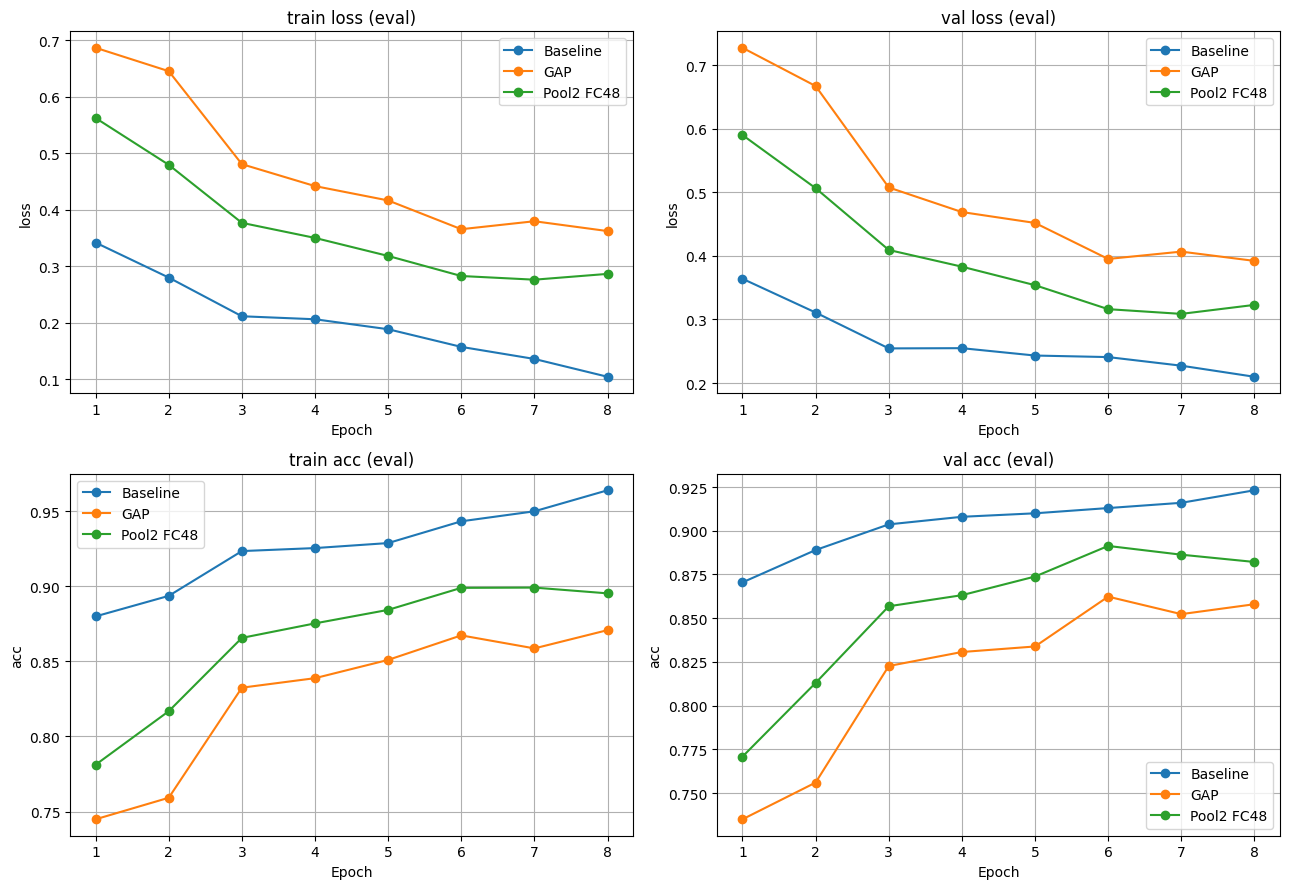

{
  "name": "A_baseline",
  "parameters": 929674,
  "epochs": 8,
  "best_loss_epoch": 8,
  "validation_loss": 0.2098998260498047,
  "validation_accuracy": 0.9231666666666667,
  "train_eval_loss": 0.10428523854414622,
  "train_eval_accuracy": 0.964,
  "train_eval_count": 6000,
  "gap_percentage_points": 4.083333333333328,
  "maximum_validation_accuracy": 0.9231666666666667,
  "maximum_accuracy_epoch": 8,
  "training_and_evaluation_seconds": 64.41176656399995,
  "parameter_reduction_percent": 0.0,
  "weight_size_FP32_MiB": 3.5464248657226562,
  "median_forward_ms": 2.1840900000142938,
  "dominated_by": ""
}
{
  "name": "D1_GAP",
  "parameters": 126730,
  "epochs": 8,
  "best_loss_epoch": 8,
  "validation_loss": 0.39208889786402384,
  "validation_accuracy": 0.858,
  "train_eval_loss": 0.3620290557543437,
  "train_eval_accuracy": 0.8708333333333333,
  "train_eval_count": 6000,
  "gap_percentage_points": 1.2833333333333363,
  "maximum_validation_accuracy": 0.8623333333333333,
  "maximum_acc

In [12]:
# D
set_seed()
result_D1 = train_model("D1_GAP", ModelD1(), trainData, trainEvalLoader, 8)
set_seed()
result_D2 = train_model("D2_Pool2_FC48", ModelD2(), trainData, trainEvalLoader, 8)
results_D = {"Baseline": result_A, "GAP": result_D1, "Pool2 FC48": result_D2}
plot_results(results_D)

fixed_batch = torch.zeros(BATCH_SIZE, 1, 28, 28).to(device)

def forward_time(model):
    model.eval()
    times = []
    with torch.no_grad():
        for _ in range(10):
            model(fixed_batch)
        synchronize()
        for _ in range(30):
            synchronize()
            start = time.perf_counter()
            model(fixed_batch)
            synchronize()
            times.append((time.perf_counter() - start) * 1000)
    return float(np.median(times))

rows_D = []
for name, result in results_D.items():
    row = dict(result["summary"])
    row["parameter_reduction_percent"] = 100 * (1 - row["parameters"] / count_parameters(baseline))
    row["weight_size_FP32_MiB"] = row["parameters"] * 4 / (1024 ** 2)
    row["median_forward_ms"] = forward_time(result["model"])
    row["dominated_by"] = ""
    rows_D.append(row)
for row in rows_D:
    row["dominated_by"] = ", ".join(other["name"] for other in rows_D
        if other["parameters"] < row["parameters"] and other["validation_accuracy"] >= row["validation_accuracy"])
for row in rows_D:
    print(json.dumps(row, indent=2))

candidates = [r for r in [result_D1, result_D2]
              if r["summary"]["parameters"] <= 0.5 * count_parameters(baseline)]
selected_result = max(candidates, key=lambda r: r["summary"]["validation_accuracy"])
selected_model = selected_result["model"]
selection = dict(selected_result["summary"])
selection["selection_rule"] = "highest checkpoint validation accuracy among compact models with <=50% baseline parameters"
selection["target_validation_accuracy"] = 0.90
selection["target_reached"] = selection["validation_accuracy"] >= 0.90
selection["parameter_limit_met"] = selection["parameters"] <= count_parameters(baseline) * 0.5
print("Selected model:", selection["name"])
print("Validation target reached:", selection["target_reached"])


{
  "baseline_correct_compact_wrong": 368,
  "baseline_wrong_compact_correct": 147,
  "top_two_new_error_classes": [
    "Coat",
    "Shirt"
  ],
  "top_two_all_error_classes": [
    "Shirt",
    "Coat"
  ],
  "shown_examples": [
    {
      "true": "Coat",
      "predicted": "Pullover"
    },
    {
      "true": "Pullover",
      "predicted": "Shirt"
    },
    {
      "true": "T-shirt/top",
      "predicted": "Shirt"
    },
    {
      "true": "Ankle boot",
      "predicted": "Sneaker"
    },
    {
      "true": "Coat",
      "predicted": "Shirt"
    }
  ]
}


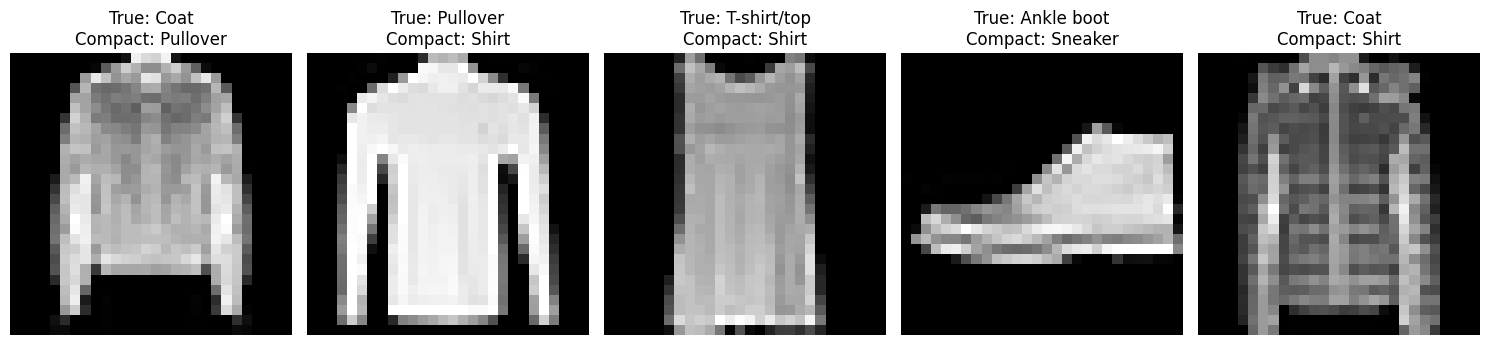

In [13]:
baseline.eval()
selected_model.eval()
new_error_counts = np.zeros(10, dtype=int)
all_error_counts = np.zeros(10, dtype=int)
new_errors = 0
fixed_errors = 0
examples = []
with torch.no_grad():
    for x, y in valLoader:
        pred_base = baseline(x.to(device)).argmax(1).cpu()
        pred_small = selected_model(x.to(device)).argmax(1).cpu()
        for i in range(len(y)):
            label = y[i].item()
            base_prediction = pred_base[i].item()
            small_prediction = pred_small[i].item()
            if small_prediction != label:
                all_error_counts[label] += 1
            if base_prediction == label and small_prediction != label:
                new_errors += 1
                new_error_counts[label] += 1
                if len(examples) < 5:
                    examples.append((x[i], label, small_prediction))
            if base_prediction != label and small_prediction == label:
                fixed_errors += 1

error_rows = []
for label in range(10):
    error_rows.append({"class": allTrainData.classes[label],
                       "all_compact_errors": int(all_error_counts[label]),
                       "new_errors_after_compression": int(new_error_counts[label])})
top_new = [i for i in np.argsort(-new_error_counts) if new_error_counts[i] > 0][:2]
top_all = [i for i in np.argsort(-all_error_counts) if all_error_counts[i] > 0][:2]
error_summary = {"baseline_correct_compact_wrong": new_errors,
                 "baseline_wrong_compact_correct": fixed_errors,
                 "top_two_new_error_classes": [allTrainData.classes[i] for i in top_new],
                 "top_two_all_error_classes": [allTrainData.classes[i] for i in top_all],
                 "shown_examples": [{"true": allTrainData.classes[y], "predicted": allTrainData.classes[p]}
                                    for image, y, p in examples]}
print(json.dumps(error_summary, indent=2))

if examples:
    plt.figure(figsize=(3 * len(examples), 4))
    for i, (image, label, prediction) in enumerate(examples):
        plt.subplot(1, len(examples), i + 1)
        plt.imshow(image.squeeze(), cmap="gray")
        plt.title("True: " + allTrainData.classes[label] + "\nCompact: " + allTrainData.classes[prediction])
        plt.axis("off")
    plt.tight_layout()
    plt.show()
    plt.close()
else:
    print("No new compression errors found.")


In [14]:
# Final Test
if "final_test_result_ex1" not in globals():
    testData = FashionMNIST("data", train=False, download=True, transform=ToTensor())
    testLoader = DataLoader(testData, batch_size=BATCH_SIZE, shuffle=False)
    test_loss, test_accuracy = evaluate(selected_model, testLoader)
    final_test_result_ex1 = {
        "model": selection["name"], "checkpoint_epoch": selection["best_loss_epoch"],
        "test_loss": test_loss, "test_accuracy": test_accuracy,
        "prior_notebook_test_viewed": True
    }
print(final_test_result_ex1)


{'model': 'D2_Pool2_FC48', 'checkpoint_epoch': 7, 'test_loss': 0.32623333768844603, 'test_accuracy': 0.8819, 'prior_notebook_test_viewed': True}
